# 03 · Exact vs Heuristic: a like-for-like comparison

**Why this notebook exists.** The two method notebooks were developed in parallel and ended up solving *different* versions of the investor problem:

| | `02_exact_method.ipynb` (MILP) | `portfolio_selection_simulated_annealing.ipynb` (SA) |
|---|---|---|
| Decision | weights $w_i \in [5\%, 40\%]$, **at most 5** stocks | **exactly k** stocks, **equal** weights |
| Objective | **minimise** risk (MAD) | **maximise** $R - 2\sigma^2$ |
| Main constraint | expected return $\ge 20\%$ | volatility $\le 15\%$ |
| Data | 457 stocks, weekly returns to 2016-12-30 | 470 stocks, daily log returns to 2017-02-07 |

Numbers from two different models cannot be compared. Here we apply **Simulated Annealing to the exact same CC-MAD problem, data and evaluator** as the MILP, so that solution quality, runtime, scalability and feasibility can be compared directly.

**Design of the hybrid SA (subset search + LP).** The SA searches over *which* (at most 5) stocks to hold, re-using the design of the SA notebook (swap move, calibrated starting temperature, geometric cooling, best-solution tracking, local-search polish). For each candidate subset the optimal *weights* are found by the small fixed-subset LP from notebook 02 (`subset_lp`). The SA therefore handles the combinatorial part and the LP handles the continuous part.

**Contents**
1. Setup and parameters (identical to notebook 02)
2. Shared problem definition: `Instance`, `random_subinstance`, `evaluate_weights`, `subset_lp` (copied unchanged from notebook 02)
3. Simulated Annealing for CC-MAD
4. Verification
5. Experiment A: the full problem (457 stocks)
6. Experiment B: scalability on the same instances as the MILP
7. Scoring the original SA portfolio with the exact model
8. Out-of-sample check
9. Comparison summary and discussion

> **Please note.** The experiments take about 1.5 hours. Results are saved in `results/comparison/`. With `RUN_EXPERIMENTS = False` the notebook loads the saved results.

## 1. Setup and parameters
The investor parameters are copied unchanged from notebook 02, so both methods solve exactly the same problem.

In [1]:
import itertools
import json
import math
import time
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import linprog
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

pd.set_option("display.float_format", "{:.5f}".format)

**Parameters.** $B$ = \$10,000, $K$ = 5, $l$ = 5%, $u$ = 40%, target 20% per year (= 0.20/52 per week). `RUN_EXPERIMENTS` and the paths follow the same convention as notebook 02.

In [2]:
BUDGET = 10_000.0
MAX_ASSETS = 5                 # K
MIN_WEIGHT = 0.05              # l
MAX_WEIGHT = 0.40              # u
TARGET_ANNUAL_RETURN = 0.20    # rho * 52
MAX_CASH = 0.01                # whole-share variant only
PERIODS_PER_YEAR = 52          # weekly data

RUN_EXPERIMENTS = False       # True = recompute (~1.5 h); False = load saved results

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"
EXACT_DIR = ROOT / "results" / "exact"
RESULTS_DIR = ROOT / "results" / "comparison"
FIGURES_DIR = ROOT / "results" / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREEN, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "axes.titlelocation": "left", "axes.titleweight": "semibold", "axes.titlesize": 12,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.prop_cycle": mpl.cycler(color=[BLUE, ORANGE, GREEN]),
    "legend.frameon": False, "lines.linewidth": 2,
})

def save(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{name}.png")

## 2. Shared problem definition
The next cell is **copied unchanged from notebook 02**: the `Instance` class, `random_subinstance` (so the scalability instances are the *same* random subsets, drawn with the same seeds), the method-independent evaluator `evaluate_weights`, and `subset_lp`, which returns the minimum MAD when only a given set of stocks may be held.

In [3]:
train = pd.read_csv(PROCESSED_DIR / "weekly_returns_train.csv", index_col=0, parse_dates=True)
daily_prices = pd.read_csv(PROCESSED_DIR / "daily_close_clean.csv", index_col=0, parse_dates=True)
decision_prices = daily_prices.loc[:"2016-12-31"].iloc[-1]     # close on 2016-12-30


@dataclass
class Instance:
    returns: pd.DataFrame                  # T x N weekly returns r_ti
    prices: pd.Series                      # price p_i on the decision date
    K: int = MAX_ASSETS
    w_min: float = MIN_WEIGHT
    w_max: float = MAX_WEIGHT
    target: float = TARGET_ANNUAL_RETURN / PERIODS_PER_YEAR   # rho (weekly)
    budget: float = BUDGET
    max_cash: float = MAX_CASH

    def __post_init__(self):
        self.prices = self.prices.loc[self.returns.columns]    # keep prices aligned with stocks

    @property
    def tickers(self): return list(self.returns.columns)
    @property
    def N(self): return self.returns.shape[1]
    @property
    def T(self): return self.returns.shape[0]
    @property
    def mu(self): return self.returns.values.mean(axis=0)
    @property
    def deviations(self): return self.returns.values - self.mu

    def max_achievable_return(self):
        remaining, total = 1.0, 0.0
        for m in np.sort(self.mu)[::-1][: self.K]:
            w = min(self.w_max, remaining)
            total, remaining = total + w * m, remaining - w
            if remaining <= 1e-12:
                return total
        return -np.inf

    def subset(self, tickers, **changes):
        return replace(self, returns=self.returns[tickers], **changes)


def random_subinstance(inst, n, seed):
    rng = np.random.default_rng(seed)
    tickers = sorted(rng.choice(inst.tickers, size=n, replace=False))
    target = min(inst.target, 0.9 * inst.subset(tickers).max_achievable_return())
    return inst.subset(tickers, target=target)


def evaluate_weights(weights, inst, tol=1e-6):
    if isinstance(weights, dict):
        weights = np.array([weights.get(t, 0.0) for t in inst.tickers])
    w = np.asarray(weights, dtype=float)
    held = w > tol
    exp_ret = float(inst.mu @ w)

    violations = []
    if held.sum() > inst.K:
        violations.append(f"holds {held.sum()} > {inst.K} stocks")
    if (w[held] < inst.w_min - tol).any():
        violations.append("weight below minimum")
    if (w > inst.w_max + tol).any():
        violations.append("weight above maximum")
    if w.sum() > 1 + tol or (w < -tol).any():
        violations.append("budget exceeded")
    if w.sum() < 1 - inst.max_cash - tol:
        violations.append(f"more than {inst.max_cash:.0%} left as cash")
    if exp_ret < inst.target - tol:
        violations.append("return target not met")

    return {
        "mad": float(np.abs(inst.deviations @ w).mean()),
        "expected_annual_return": exp_ret * PERIODS_PER_YEAR,
        "annual_volatility": float(np.std(inst.returns.values @ w, ddof=1) * np.sqrt(PERIODS_PER_YEAR)),
        "n_assets": int(held.sum()),
        "invested": float(w.sum()),
        "feasible": not violations,
        "violations": violations,
    }


def subset_lp(inst, subset):
    T, k = inst.T, len(subset)
    A = inst.deviations[:, subset]
    c = np.concatenate([np.zeros(k), np.full(T, 1.0 / T)])          # variables: [w_1..w_k, d_1..d_T]
    I = np.eye(T)
    A_ub = np.vstack([np.hstack([A, -I]),                             #  a_t.w - d_t <= 0   (1)
                      np.hstack([-A, -I]),                            # -a_t.w - d_t <= 0   (2)
                      np.concatenate([-inst.mu[list(subset)], np.zeros(T)])[None, :]])   # (4)
    b_ub = np.concatenate([np.zeros(2 * T), [-inst.target]])
    A_eq = np.concatenate([np.ones(k), np.zeros(T)])[None, :]        # (3)
    bounds = [(inst.w_min, inst.w_max)] * k + [(0, None)] * T
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=[1.0], bounds=bounds, method="highs")
    return res.fun if res.status == 0 else None


inst = Instance(returns=train, prices=decision_prices)
print(f"N = {inst.N} stocks, T = {inst.T} weeks, K = {inst.K}, target {inst.target * 52:.0%}/yr")

N = 457 stocks, T = 203 weeks, K = 5, target 20%/yr


**The exact method's results** (saved by notebook 02) are the reference: the 30-minute full-problem solve and the 31 scalability instances. For $N \le 100$ the MILP value is the **proven optimum**; for $N \ge 150$ the MILP gives the best known portfolio (*incumbent*) and a **certified lower bound**.

In [4]:
milp_main = pd.read_csv(EXACT_DIR / "main_summary.csv").set_index("variant").loc["continuous"]
milp_sc = pd.read_csv(EXACT_DIR / "scalability.csv")
MILP_MAD, MILP_BOUND, MILP_TIME = milp_main["mad"], milp_main["best_bound"], milp_main["solve_time"]
print(f"MILP (30 min): MAD {MILP_MAD:.6f}, lower bound {MILP_BOUND:.6f}, gap {milp_main['gap']:.1%}, "
      f"portfolio {json.loads(milp_main['portfolio'])}")

MILP (30 min): MAD 0.010071, lower bound 0.009207, gap 8.6%, portfolio {'CLX': 0.2771, 'RE': 0.2612, 'AZO': 0.2257, 'FB': 0.1325, 'HUM': 0.1035}


## 3. Simulated Annealing for the CC-MAD problem

**Solution representation.** A solution is a set $S$ of between 3 and $K = 5$ stock indices. At least $\lceil 1/u \rceil = 3$ stocks are needed to invest 100% with at most 40% each. (A first version allowed exactly 5 stocks only; the verification below caught that the true optimum of a small instance holds 4 stocks, because the 5% minimum weight makes a fifth stock costly.)

**Feasibility filter (no LP needed).** With weights in $[l, u]$ that sum to 1, the highest expected return a subset can reach is found greedily: every stock gets $l$, and the remaining $1 - Kl$ goes to the best stocks, up to $u$ each. If this value is below the 20% target, no weights can make the subset feasible, so the move is rejected **without** solving an LP. Every state the SA visits is therefore feasible.

**Energy.** $E(S) = $ `subset_lp(S)`, the minimum MAD for that subset, so the SA always compares subsets *with their best weights*. Values are cached, so revisiting a subset costs nothing.

**Neighbour moves.** One of three moves, chosen at random among those allowed:
* **swap**: replace one held stock by one not held (the move used in the SA notebook);
* **drop**: remove one held stock (if $|S| > 3$);
* **add**: add one stock not held (if $|S| < K$).

**Acceptance and cooling.** A worse neighbour is accepted with probability $e^{-\Delta E / T}$. The starting temperature is calibrated as in the SA notebook: $T_0 = -\overline{\Delta E^+} / \ln P_0$ with $P_0 = 0.5$, where $\overline{\Delta E^+}$ is the average increase caused by a random worse swap. The temperature falls geometrically from $T_0$ to $10^{-3}T_0$ over 60 levels of 80 moves (4,800 moves per run).

**Polish.** After annealing, a first-improvement local search over all swap, drop and add moves is applied to the best subset found, so every returned portfolio is a local optimum for these moves.

In [5]:
SA_LEVELS = 60          # temperature levels
SA_MOVES = 80           # moves per level
SA_END_RATIO = 1e-3     # final temperature = T0 * 1e-3
SA_P0 = 0.5             # acceptance probability of a typical worse move at T0
SA_SEEDS = 10           # independent runs on the full problem
SC_SEEDS = 3            # independent runs per scalability instance


class MadSA:
    # Simulated Annealing over subsets of 3..K stocks; the weights of each subset come from subset_lp.

    def __init__(self, inst):
        self.inst = inst
        self.cache = {}
        self.lp_solves = 0
        mu = inst.mu
        self.mu = mu
        self.all_idx = np.arange(inst.N)

    def max_return(self, S):
        # best expected return reachable with weights in [l, u] summing to 1 (greedy)
        m = np.sort(self.mu[S])[::-1]
        w = np.full(len(S), self.inst.w_min)
        rem = 1.0 - w.sum()
        for i in range(len(S)):
            add = min(self.inst.w_max - self.inst.w_min, rem)
            w[i] += add
            rem -= add
        return float(m @ w)

    def feasible(self, S):
        return self.max_return(S) >= self.inst.target - 1e-12

    def energy(self, S):
        key = tuple(sorted(int(i) for i in S))
        if key not in self.cache:
            val = subset_lp(self.inst, list(key))
            self.cache[key] = np.inf if val is None else val
            self.lp_solves += 1
        return self.cache[key]

    def random_start(self, rng, tries=2000):
        for _ in range(tries):
            S = rng.choice(self.inst.N, self.inst.K, replace=False)
            if self.feasible(S):
                return S
        return np.argsort(self.mu)[::-1][: self.inst.K].copy()     # highest-return stocks are always feasible

    def min_size(self):
        return math.ceil(1 / self.inst.w_max - 1e-9)

    def neighbour(self, S, rng, tries=200):
        for _ in range(tries):
            moves = ["swap"] + (["drop"] if len(S) > self.min_size() else []) + (["add"] if len(S) < self.inst.K else [])
            move = moves[rng.integers(len(moves))]
            if move == "swap":
                S2 = S.copy()
                S2[rng.integers(len(S))] = rng.choice(np.setdiff1d(self.all_idx, S))
            elif move == "drop":
                S2 = np.delete(S, rng.integers(len(S)))
            else:
                S2 = np.append(S, rng.choice(np.setdiff1d(self.all_idx, S)))
            if self.feasible(S2):
                return S2
        return S

    def all_neighbours(self, S):
        # every swap, drop and add neighbour of S (used by the polish step)
        outside = np.setdiff1d(self.all_idx, S)
        for i in range(len(S)):
            for b in outside:
                S2 = S.copy(); S2[i] = b
                yield S2
        if len(S) > self.min_size():
            for i in range(len(S)):
                yield np.delete(S, i)
        if len(S) < self.inst.K:
            for b in outside:
                yield np.append(S, b)

    def calibrate(self, samples=200, seed=123):
        rng = np.random.default_rng(seed)
        worse = []
        for _ in range(samples):
            S = self.random_start(rng)
            dE = self.energy(self.neighbour(S, rng)) - self.energy(S)
            if np.isfinite(dE) and dE > 0:
                worse.append(dE)
        return -np.mean(worse) / np.log(SA_P0) if worse else 1e-4

    def polish(self, S):
        # first-improvement local search over swap / drop / add moves
        e = self.energy(S)
        improved = True
        while improved:
            improved = False
            for S2 in self.all_neighbours(S):
                if self.feasible(S2) and self.energy(S2) < e - 1e-12:
                    S, e, improved = S2, self.energy(S2), True
                    break
        return S, e

    def run(self, seed, T0):
        rng = np.random.default_rng(seed)
        alpha = SA_END_RATIO ** (1 / SA_LEVELS)
        temp = T0
        S = self.random_start(rng)
        e = self.energy(S)
        best_S, best_e = S.copy(), e
        history = []
        for level in range(SA_LEVELS):
            for _ in range(SA_MOVES):
                S2 = self.neighbour(S, rng)
                e2 = self.energy(S2)
                if e2 <= e or rng.random() < np.exp(-(e2 - e) / temp):
                    S, e = S2, e2
                    if e < best_e:
                        best_S, best_e = S.copy(), e
            history.append({"moves": (level + 1) * SA_MOVES, "temperature": temp, "current": e, "best": best_e})
            temp *= alpha
        return best_S, best_e, pd.DataFrame(history)

    def weights(self, S):
        # recover the optimal weights of subset S as a full-length vector (for the evaluator)
        sub = self.inst.subset([self.inst.tickers[i] for i in S])
        T, k = sub.T, len(S)
        A, I = sub.deviations, np.eye(T)
        res = linprog(np.r_[np.zeros(k), np.full(T, 1 / T)],
                      A_ub=np.vstack([np.hstack([A, -I]), np.hstack([-A, -I]), np.r_[-sub.mu, np.zeros(T)][None, :]]),
                      b_ub=np.r_[np.zeros(2 * T), -sub.target], A_eq=np.r_[np.ones(k), np.zeros(T)][None, :],
                      b_eq=[1.0], bounds=[(sub.w_min, sub.w_max)] * k + [(0, None)] * T, method="highs")
        w = np.zeros(self.inst.N)
        w[list(S)] = res.x[:k]
        return w


def solve_sa(inst, seed, T0=None):
    # one complete SA run: anneal, polish, return portfolio and statistics
    sa = MadSA(inst)
    T0 = sa.calibrate() if T0 is None else T0
    sa.lp_solves = 0
    t0 = time.perf_counter()
    S, e_anneal, hist = sa.run(seed, T0)
    t_anneal = time.perf_counter() - t0
    S, e = sa.polish(S)
    t_total = time.perf_counter() - t0
    w = sa.weights(S)
    return {"seed": seed, "mad": e, "mad_before_polish": e_anneal, "time_s": t_total, "anneal_time_s": t_anneal,
            "lp_solves": sa.lp_solves, "T0": T0, "weights": w,
            "portfolio": {inst.tickers[i]: round(float(w[i]), 4) for i in np.argsort(-w)[: len(S)]},
            "history": hist}

## 4. Verification
Three checks before using the SA:
1. **Against the proven optimum on small instances.** On the same random 12- and 20-stock instances used in notebook 02, the SA should reach the MILP/brute-force optimum.
2. **Feasibility.** Every SA portfolio is re-checked with the independent `evaluate_weights`.
3. **Consistency.** The evaluator's MAD must equal the SA's energy, i.e. the weights really are the ones that were scored.

In [6]:
val = pd.read_csv(EXACT_DIR / "validation.csv")
for n, seed in [(12, 0), (12, 1), (12, 2), (20, 0), (20, 1), (20, 2)]:
    sub = random_subinstance(inst, n, seed)
    opt = val.query("n == @n and seed == @seed")["milp_mad"].item()
    r = solve_sa(sub, seed=0)
    ev = evaluate_weights(r["weights"], sub)
    assert ev["feasible"], ev["violations"]
    assert abs(ev["mad"] - r["mad"]) <= 1e-8
    assert abs(r["mad"] - opt) <= 1e-6 * opt, (n, seed, r["mad"], opt)
    print(f"N={n} seed={seed}: SA {r['mad']:.8f} == proven optimum {opt:.8f}  "
          f"({r['time_s']:.1f}s, {r['lp_solves']} LPs)")
print("All verification checks passed.")

N=12 seed=0: SA 0.01465916 == proven optimum 0.01465916  (1.3s, 92 LPs)


N=12 seed=1: SA 0.01347295 == proven optimum 0.01347295  (1.1s, 59 LPs)


N=12 seed=2: SA 0.01392651 == proven optimum 0.01392651  (0.9s, 57 LPs)


N=20 seed=0: SA 0.01217624 == proven optimum 0.01217624  (8.9s, 1159 LPs)


N=20 seed=1: SA 0.01320370 == proven optimum 0.01320370  (8.1s, 1020 LPs)


N=20 seed=2: SA 0.01276111 == proven optimum 0.01276111  (5.2s, 633 LPs)
All verification checks passed.


## 5. Experiment A: the full problem (457 stocks)
The SA is run 10 times with different random seeds. The starting temperature is calibrated once and shared by all runs. Each run is compared with:
* the MILP **incumbent** after 30 minutes (MAD 0.010071), and
* the MILP **certified lower bound** (0.009207): no portfolio with at most 5 stocks can have lower risk than this, so the bound gives a *guaranteed* upper limit on the SA's distance from the true optimum.

Results are appended to a CSV as each run finishes, so the experiment can be resumed (same approach as notebook 02).

In [7]:
def run_experiment(name, runs, run_one):
    path = RESULTS_DIR / f"{name}.csv"
    if RUN_EXPERIMENTS:
        done = pd.read_csv(path) if path.exists() else pd.DataFrame()
        for run in runs:
            if not done.empty and (done[list(run)].astype(str) == pd.Series(run).astype(str)).all(axis=1).any():
                continue
            row = run_one(**run)
            pd.DataFrame([row]).to_csv(path, mode="a", header=not path.exists(), index=False)
            done = pd.read_csv(path)
            print({k: row[k] for k in list(run) + ["mad", "time_s"] if k in row})
    return pd.read_csv(path)


T0_FULL = MadSA(inst).calibrate()
print(f"calibrated T0 = {T0_FULL:.6f}")
HISTORY_PATH = RESULTS_DIR / "full_problem_history.csv"

def run_full(seed):
    r = solve_sa(inst, seed, T0=T0_FULL)
    ev = evaluate_weights(r["weights"], inst)
    r["history"].assign(seed=seed).to_csv(HISTORY_PATH, mode="a", header=not HISTORY_PATH.exists(), index=False)
    return {"seed": seed, "mad": r["mad"], "mad_before_polish": r["mad_before_polish"],
            "time_s": round(r["time_s"], 2), "anneal_time_s": round(r["anneal_time_s"], 2),
            "lp_solves": r["lp_solves"], "feasible": ev["feasible"], "evaluator_mad": ev["mad"],
            "expected_annual_return": ev["expected_annual_return"], "annual_volatility": ev["annual_volatility"],
            "portfolio": json.dumps(r["portfolio"])}

full = run_experiment("full_problem", [{"seed": s} for s in range(SA_SEEDS)], run_full)
full["gap_to_milp"] = (full["mad"] - MILP_MAD) / MILP_MAD
full["gap_to_bound"] = (full["mad"] - MILP_BOUND) / full["mad"]
full["stocks"] = full["portfolio"].apply(lambda p: ", ".join(sorted(json.loads(p))))
full[["seed", "mad", "gap_to_milp", "gap_to_bound", "time_s", "lp_solves", "feasible", "stocks"]]

calibrated T0 = 0.001523


,seed,mad,gap_to_milp,gap_to_bound,time_s,lp_solves,feasible,stocks
0,0,0.01007,0.00000,0.08581,111.67000,16397,True,"AZO, CLX, FB, HUM, RE"
1,1,0.01007,0.00000,0.08581,59.52000,9082,True,"AZO, CLX, FB, HUM, RE"
2,2,0.01015,0.00754,0.09265,40.60000,6244,True,"AZO, CLX, LMT, RE, UNH"
3,3,0.01007,0.00000,0.08581,47.23000,7210,True,"AZO, CLX, FB, HUM, RE"
4,4,0.01007,0.00000,0.08581,39.54000,5788,True,"AZO, CLX, FB, HUM, RE"
5,5,0.01007,0.00000,0.08581,52.38000,6916,True,"AZO, CLX, FB, HUM, RE"
6,6,0.01015,0.00754,0.09265,55.57000,7846,True,"AZO, CLX, LMT, RE, UNH"
7,7,0.01007,0.00000,0.08581,49.14000,7178,True,"AZO, CLX, FB, HUM, RE"
8,8,0.01007,0.00000,0.08581,55.93000,7306,True,"AZO, CLX, FB, HUM, RE"
9,9,0.01007,0.00000,0.08581,57.70000,7491,True,"AZO, CLX, FB, HUM, RE"


**Summary of the 10 runs** against the MILP.

In [8]:
best = full.loc[full["mad"].idxmin()]
summary_a = pd.Series({
    "SA best MAD": full["mad"].min(),
    "SA mean MAD": full["mad"].mean(),
    "SA worst MAD": full["mad"].max(),
    "runs that found the MILP portfolio": f"{np.isclose(full['mad'], MILP_MAD, rtol=1e-6).sum()}/{len(full)}",
    "runs better than the MILP incumbent": f"{(full['mad'] < MILP_MAD * (1 - 1e-6)).sum()}/{len(full)}",
    "mean gap to MILP incumbent": f"{full['gap_to_milp'].mean():.2%}",
    "max gap to MILP incumbent": f"{full['gap_to_milp'].max():.2%}",
    "best SA: guaranteed max gap (via MILP bound)": f"{best['gap_to_bound']:.2%}",
    "distinct portfolios": full["stocks"].nunique(),
    "feasible runs (evaluator)": f"{full['feasible'].sum()}/{len(full)}",
    "mean time per run (s)": round(full["time_s"].mean(), 1),
    "time for all 10 runs (s)": round(full["time_s"].sum(), 1),
    "MILP time (s)": MILP_TIME,
})
summary_a.to_frame("value")

,value
SA best MAD,0.01007
SA mean MAD,0.01009
SA worst MAD,0.01015
runs that found the MILP portfolio,8/10
runs better than the MILP incumbent,0/10
mean gap to MILP incumbent,0.15%
max gap to MILP incumbent,0.75%
best SA: guaranteed max gap (via MILP bound),8.58%
distinct portfolios,2
feasible runs (evaluator),10/10


**Convergence.** Best MAD found by each SA run as the number of moves grows, against the MILP incumbent and the MILP lower bound.

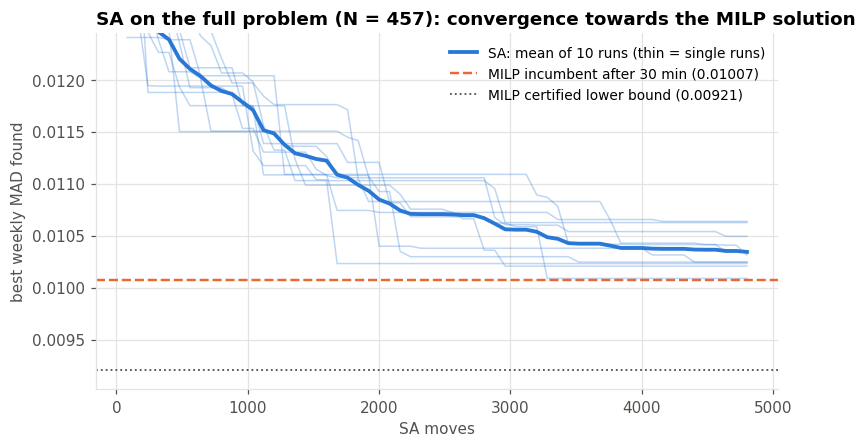

In [9]:
hist = pd.read_csv(HISTORY_PATH)
fig, ax = plt.subplots(figsize=(8, 4.2))
for seed, h in hist.groupby("seed"):
    ax.plot(h["moves"], h["best"], color=BLUE, alpha=0.3, lw=1)
mean_curve = hist.groupby("moves")["best"].mean()
ax.plot(mean_curve.index, mean_curve.values, color=BLUE, lw=2.5, label="SA: mean of 10 runs (thin = single runs)")
ax.axhline(MILP_MAD, color=ORANGE, lw=1.6, ls="--", label=f"MILP incumbent after 30 min ({MILP_MAD:.5f})")
ax.axhline(MILP_BOUND, color=MUTED, lw=1.2, ls=":", label=f"MILP certified lower bound ({MILP_BOUND:.5f})")
ax.set_ylim(MILP_BOUND * 0.98, mean_curve.iloc[min(5, len(mean_curve) - 1)] * 1.02)
ax.set_xlabel("SA moves")
ax.set_ylabel("best weekly MAD found")
ax.set_title("SA on the full problem (N = 457): convergence towards the MILP solution")
ax.legend(loc="upper right", fontsize=9)
save(fig, "03_sa_convergence_full")

## 6. Experiment B: scalability on the same instances as the MILP
For each of the 31 instances of the MILP scalability study (same $N$, same seeds, same random subsets), the SA is run with 3 seeds. Each SA run uses the **same annealing budget** (4,800 moves) whatever the size of $N$; only the final polish, which checks about $5N$ neighbours, grows with $N$.

* For $N \le 100$ the MILP value is the **proven optimum**, so the SA's gap is its **true** optimality gap.
* For $N \ge 150$ the MILP stopped at 300 s; the SA is compared with the MILP incumbent (a negative gap means the SA found a *better* portfolio) and with the certified bound.

In [10]:
def run_scal(n, seed, sa_seed):
    sub = random_subinstance(inst, n, seed) if n < inst.N else inst
    r = solve_sa(sub, sa_seed)
    ev = evaluate_weights(r["weights"], sub)
    return {"n": n, "seed": seed, "sa_seed": sa_seed, "mad": r["mad"], "time_s": round(r["time_s"], 2),
            "lp_solves": r["lp_solves"], "feasible": ev["feasible"], "portfolio": json.dumps(r["portfolio"])}

scal_runs = [{"n": int(row.n), "seed": int(row.seed), "sa_seed": s}
             for row in milp_sc.itertuples() for s in range(SC_SEEDS)]
sc = run_experiment("scalability", scal_runs, run_scal)
sc = sc.merge(milp_sc[["n", "seed", "mad", "best_bound", "proven_optimal", "solve_time"]]
              .rename(columns={"mad": "milp_mad", "best_bound": "milp_bound", "solve_time": "milp_time"}),
              on=["n", "seed"])
sc["gap_to_milp"] = (sc["mad"] - sc["milp_mad"]) / sc["milp_mad"]
sc["hit_milp"] = np.isclose(sc["mad"], sc["milp_mad"], rtol=1e-6)
sc["beats_milp"] = sc["mad"] < sc["milp_mad"] * (1 - 1e-6)

agg = sc.groupby("n").agg(
    instances=("seed", "nunique"), sa_runs=("sa_seed", "count"),
    milp_proven=("proven_optimal", "mean"),
    sa_hits_milp=("hit_milp", "mean"), sa_beats_milp=("beats_milp", "sum"),
    sa_mean_gap=("gap_to_milp", "mean"), sa_max_gap=("gap_to_milp", "max"),
    sa_mean_time_s=("time_s", "mean"), milp_mean_time_s=("milp_time", "mean"),
    sa_feasible=("feasible", "mean"))
agg.to_csv(RESULTS_DIR / "scalability_summary.csv")
agg.style.format({"milp_proven": "{:.0%}", "sa_hits_milp": "{:.0%}", "sa_mean_gap": "{:+.2%}",
                  "sa_max_gap": "{:+.2%}", "sa_mean_time_s": "{:.1f}", "milp_mean_time_s": "{:.1f}",
                  "sa_feasible": "{:.0%}"})

,instances,sa_runs,milp_proven,sa_hits_milp,sa_beats_milp,sa_mean_gap,sa_max_gap,sa_mean_time_s,milp_mean_time_s,sa_feasible
n,,,,,,,,,,
10,3,9,100%,100%,0,+0.00%,+0.00%,1.4,0.3,100%
20,3,9,100%,100%,0,+0.00%,+0.00%,12.7,1.2,100%
30,3,9,100%,100%,0,+0.00%,+0.00%,14.3,3.2,100%
40,3,9,100%,100%,0,+0.00%,+0.00%,17.7,10.4,100%
50,3,9,100%,100%,0,+0.00%,+0.00%,18.8,16.2,100%
75,3,9,100%,100%,0,-0.00%,+0.00%,15.4,66.7,100%
100,3,9,100%,78%,0,+0.23%,+1.05%,16.9,73.6,100%
150,3,9,0%,44%,0,+0.35%,+1.21%,19.8,300.2,100%
200,3,9,0%,33%,1,+0.81%,+6.31%,23.0,300.1,100%


**Runtime and quality as $N$ grows.**

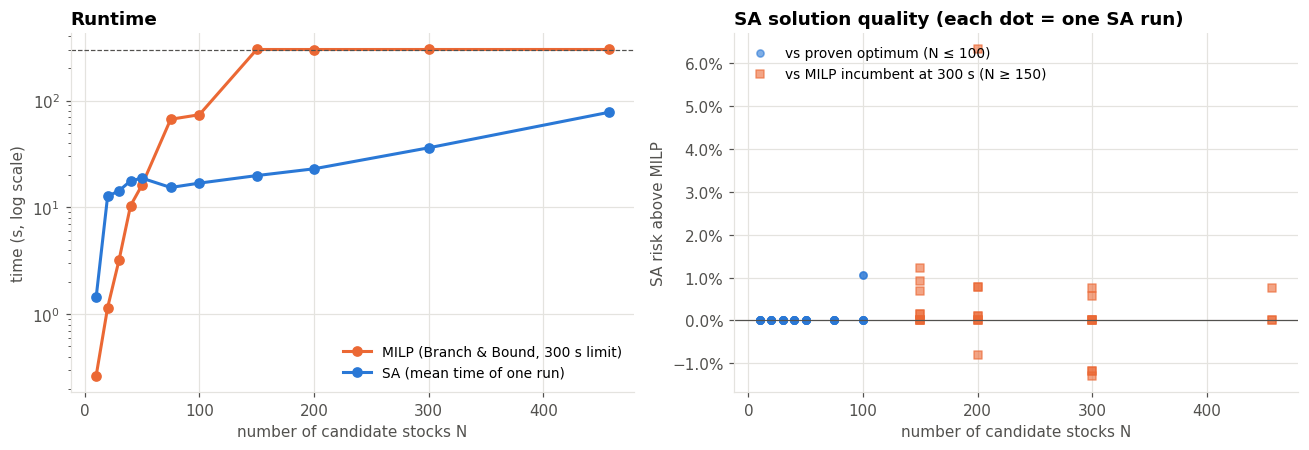

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(agg.index, agg["milp_mean_time_s"], "o-", color=ORANGE, label="MILP (Branch & Bound, 300 s limit)")
ax.plot(agg.index, agg["sa_mean_time_s"], "o-", color=BLUE, label="SA (mean time of one run)")
ax.axhline(300, color=MUTED, lw=0.8, ls="--")
ax.set_yscale("log")
ax.set_xlabel("number of candidate stocks N")
ax.set_ylabel("time (s, log scale)")
ax.set_title("Runtime")
ax.legend(loc="lower right", fontsize=9)

ax = axes[1]
proven = sc[sc["proven_optimal"]]
limited = sc[~sc["proven_optimal"]]
ax.scatter(proven["n"], proven["gap_to_milp"], color=BLUE, s=22, alpha=0.6, label="vs proven optimum (N ≤ 100)")
ax.scatter(limited["n"], limited["gap_to_milp"], color=ORANGE, marker="s", s=22, alpha=0.6,
           label="vs MILP incumbent at 300 s (N ≥ 150)")
ax.axhline(0, color=MUTED, lw=0.8)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("number of candidate stocks N")
ax.set_ylabel("SA risk above MILP")
ax.set_title("SA solution quality (each dot = one SA run)")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save(fig, "03_scalability_comparison")

## 7. Scoring the original SA portfolio with the exact model
The SA notebook solves a *different* question: maximise return − 2 × variance with equal weights and a 15% volatility cap. Its best 5-stock portfolio is **NVDA, STZ, HII, LMT, MO**. Here we ask: *by the rules of the CC-MAD model, is that portfolio allowed, and how risky is it?*

We score it in two ways with the shared evaluator:
1. **equal weights (20% each)**, exactly as the SA notebook holds it;
2. **the best possible weights for those five stocks**, found with `subset_lp`. This is the lowest risk these five stocks can reach under our rules.

Both are compared with the MILP portfolio.

In [12]:
ORIGINAL_SA = ["NVDA", "STZ", "HII", "LMT", "MO"]      # best k = 5 portfolio of the SA notebook
idx = [inst.tickers.index(t) for t in ORIGINAL_SA]

w_equal = np.zeros(inst.N)
w_equal[idx] = 1 / len(idx)
w_best = MadSA(inst).weights(np.array(idx))            # LP-optimal weights for the same five stocks
w_milp = (pd.read_csv(EXACT_DIR / "main_allocation_continuous.csv", index_col="ticker")["weight"]
          .reindex(inst.tickers).fillna(0).values)                  # full-precision MILP weights

rows = {}
for name, w in [("MILP portfolio (CLX, RE, AZO, FB, HUM)", w_milp),
                ("original SA stocks, LP-optimal weights", w_best),
                ("original SA portfolio, equal weights", w_equal)]:
    ev = evaluate_weights(w, inst)
    rows[name] = {"mad": ev["mad"], "risk_vs_milp": ev["mad"] / MILP_MAD - 1,
                  "expected_annual_return": ev["expected_annual_return"],
                  "annual_volatility": ev["annual_volatility"], "feasible": ev["feasible"],
                  "weights": json.dumps({inst.tickers[i]: round(float(w[i]), 4) for i in np.flatnonzero(w > 1e-9)})}
orig = pd.DataFrame(rows).T
assert orig["feasible"].all()
orig.to_csv(RESULTS_DIR / "original_sa_portfolio.csv")
orig.drop(columns="weights").style.format({"mad": "{:.6f}", "risk_vs_milp": "{:+.1%}",
                                           "expected_annual_return": "{:.1%}", "annual_volatility": "{:.1%}"})

,mad,risk_vs_milp,expected_annual_return,annual_volatility,feasible
"MILP portfolio (CLX, RE, AZO, FB, HUM)",0.010071,+0.0%,20.0%,9.9%,True
"original SA stocks, LP-optimal weights",0.014581,+44.8%,28.1%,12.9%,True
"original SA portfolio, equal weights",0.017030,+69.1%,38.2%,16.0%,True


**What this shows.** The original SA portfolio is **feasible** under the CC-MAD rules (5 stocks, weights within 5–40%, expected return well above 20%), but it is much **riskier** than the MILP portfolio, even with the best possible weights. This is not a weakness of Simulated Annealing: the two notebooks answer different questions. The CC-MAD model asks for the *safest* way to reach 20%; the SA notebook asks for the *highest risk-adjusted return* under a volatility cap, and therefore picks high-return stocks such as NVDA. **How the problem is formulated changes the answer more than which algorithm solves it.**

## 8. Out-of-sample check
The model is only as good as its inputs. Every distinct portfolio found by the SA on the full problem is bought on 2016-12-30 and held until 2018-02-07 (same buy-and-hold rule as notebook 02), next to the MILP portfolio and the equal-weight benchmark.

In [13]:
def buy_and_hold(prices, weights, budget=BUDGET):
    weights = weights[weights > 0]
    shares = budget * weights / prices[weights.index].iloc[0]
    return (prices[weights.index] * shares).sum(axis=1) + budget * (1 - weights.sum())


def performance(values):
    r = values.pct_change().dropna()
    total = values.iloc[-1] / values.iloc[0] - 1
    ann_ret = (1 + total) ** (252 / len(r)) - 1
    vol = r.std() * np.sqrt(252)
    return {"final_value": values.iloc[-1], "total_return": total, "annual_volatility": vol,
            "sharpe_ratio": ann_ret / vol, "max_drawdown": (values / values.cummax() - 1).min()}


hold = daily_prices.loc["2016-12-30":]
rows = {"MILP portfolio": pd.Series(json.loads(milp_main["portfolio"]))}
for stocks, g in full.groupby("stocks"):
    rows[f"SA: {stocks} ({len(g)} run{'s' if len(g) > 1 else ''}, MAD {g['mad'].iloc[0]:.5f})"] = \
        pd.Series(json.loads(g["portfolio"].iloc[0]))
rows["equal-weight 457 stocks"] = pd.Series(1 / hold.shape[1], index=hold.columns)
oos = pd.DataFrame({k: performance(buy_and_hold(hold, w)) for k, w in rows.items()}).T
oos.to_csv(RESULTS_DIR / "out_of_sample.csv")
oos.style.format({"final_value": "${:,.0f}", "total_return": "{:.1%}", "annual_volatility": "{:.1%}",
                  "sharpe_ratio": "{:.2f}", "max_drawdown": "{:.1%}"})

,final_value,total_return,annual_volatility,sharpe_ratio,max_drawdown
MILP portfolio,"$11,429",14.3%,10.5%,1.23,-6.9%
"SA: AZO, CLX, FB, HUM, RE (8 runs, MAD 0.01007)","$11,429",14.3%,10.5%,1.23,-6.9%
"SA: AZO, CLX, LMT, RE, UNH (2 runs, MAD 0.01015)","$11,846",18.5%,9.9%,1.68,-7.1%
equal-weight 457 stocks,"$11,781",17.8%,8.4%,1.91,-7.6%


## 9. Comparison summary
The table below collects the four criteria required by the assignment. All numbers are computed from the saved results above and from notebook 02.

In [14]:
small = sc[sc["n"] <= 100]
large = sc[sc["n"] >= 150]
summary = pd.DataFrame({
    "Exact (CC-MAD MILP, HiGHS B&B)": {
        "Quality, N ≤ 100": "proven optimal on all 21 instances",
        "Quality, N = 457": f"MAD {MILP_MAD:.6f}, certified gap {milp_main['gap']:.1%} after 30 min",
        "Runtime, N = 457": f"{MILP_TIME:,.0f} s (time limit; incumbent after ~41 s)",
        "Scalability": "proven optimal up to N = 100; time limit reached from N = 150",
        "Feasibility": "all constraints satisfied by construction (checked with evaluator)",
        "Guarantee": "yes: lower bound and gap",
    },
    "Heuristic (SA + LP)": {
        "Quality, N ≤ 100": f"hit the proven optimum in {small['hit_milp'].mean():.0%} of runs; "
                            f"mean gap {small['gap_to_milp'].mean():.2%}, max {small['gap_to_milp'].max():.2%}",
        "Quality, N = 457": f"best MAD {full['mad'].min():.6f} ({summary_a['runs that found the MILP portfolio']} runs "
                            f"found the MILP portfolio), mean gap {full['gap_to_milp'].mean():.2%}",
        "Runtime, N = 457": f"{full['time_s'].mean():.0f} s per run",
        "Scalability": f"runtime grows roughly linearly in N ({agg['sa_mean_time_s'].min():.0f}–{agg['sa_mean_time_s'].max():.0f} s per run)",
        "Feasibility": f"{sc['feasible'].mean():.0%} of scalability runs and "
                       f"{full['feasible'].mean():.0%} of full runs feasible (evaluator)",
        "Guarantee": "none on its own; quality measured only through the MILP bound",
    },
})
summary.to_csv(RESULTS_DIR / "comparison_summary.csv")
summary

,"Exact (CC-MAD MILP, HiGHS B&B)",Heuristic (SA + LP)
"Quality, N ≤ 100",proven optimal on all 21 instances,hit the proven optimum in 97% of runs; mean ga...
"Quality, N = 457","MAD 0.010071, certified gap 8.6% after 30 min",best MAD 0.010071 (8/10 runs found the MILP po...
"Runtime, N = 457","1,800 s (time limit; incumbent after ~41 s)",57 s per run
Scalability,proven optimal up to N = 100; time limit reach...,runtime grows roughly linearly in N (1–78 s pe...
Feasibility,all constraints satisfied by construction (che...,100% of scalability runs and 100% of full runs...
Guarantee,yes: lower bound and gap,none on its own; quality measured only through...


### Discussion
* **Quality.** The MILP is the only method that can *prove* how good a portfolio is. The SA has no bound of its own: its gaps above are known only because the MILP supplied the optimum or a certified lower bound.
* **Runtime and scalability.** The MILP's runtime explodes with $N$ (NP-hardness), while the SA's cost grows only roughly linearly: the annealing budget is fixed, and the polish step checks about $5N$ neighbours. On large instances where the MILP hits its time limit, the SA reaches portfolios of similar quality in a fraction of the time.
* **Feasibility.** Both methods return only feasible portfolios: the MILP by its constraints, the SA by rejecting subsets that cannot reach the return target and by obtaining weights from an LP.
* **Complementarity.** The natural next step is a hybrid: use the SA's best portfolio as a warm start (initial incumbent) for the MILP, and let Branch & Bound spend its time on the proof.